# 🧠 Notebook 03 · Model Architecture & Training
**PestAlertNet v2** | Desert Locust Outbreak Early-Warning System

---
## Overview

This notebook describes the **HybridOutbreakModel** — a dual-branch deep learning architecture
combining:

- **Bidirectional LSTM** — captures temporal order and long-range dependencies
- **Multi-Head Self-Attention (Transformer)** — captures global cross-time correlations
- **MLP Classifier** — fuses representations for binary outbreak prediction

```
Input [B, 21, 25]
   ├─► 2-layer BiLSTM ──► last-step pool ──► [B, 256]
   │                                              ├─► concat ──► [B, 512] ──► MLP ──► logit [B]
   └─► Linear(25→256) ──► Pos-Emb ──► 2×Transformer ──► last-step ──► [B, 256]
```


In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys, os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import json

plt.rcParams.update({
    "figure.facecolor": "#0d1117",
    "axes.facecolor":   "#161b22",
    "axes.edgecolor":   "#30363d",
    "axes.labelcolor":  "#c9d1d9",
    "xtick.color":      "#8b949e",
    "ytick.color":      "#8b949e",
    "text.color":       "#c9d1d9",
    "grid.color":       "#21262d",
    "grid.linestyle":   "--",
    "grid.alpha":       0.6,
    "figure.dpi":       130,
    "font.size":        11,
})

GREEN  = "#3fb950"
AMBER  = "#d29922"
RED    = "#f85149"
CYAN   = "#79c0ff"
PURPLE = "#bc8cff"

nb_dir = os.path.abspath(".")
PROJECT_ROOT = os.path.dirname(nb_dir) if os.path.basename(nb_dir)=="notebooks" else nb_dir

import torch
import torch.nn as nn
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available:  {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device:          {device}")


PyTorch version: 2.14.1+cpu
CUDA available:  False
Device:          cpu


## 1 · HybridOutbreakModel Architecture


In [2]:
# ── Load and inspect the model definition ────────────────────────────────────
model_src = os.path.join(PROJECT_ROOT, "src", "model", "hybrid_outbreak_model.py")
with open(model_src) as f:
    src_text = f.read()
print(src_text[:1200] + "\n... [truncated for display] ...")


import torch
import torch.nn as nn
from torch.nn import TransformerEncoder, TransformerEncoderLayer

__all__ = ['HybridOutbreakModel']


class HybridOutbreakModel(nn.Module):
    """Hybrid LSTM + Transformer outbreak risk model.

    Architecture (approved):
      input: [B, 21, 25] float32
      -> 2-layer bidirectional LSTM, hidden_size=128
         -> last-time-step pooling -> [B, 256]
      -> Transformer branch: Linear(25->256), learned positional embedding (21),
         2 TransformerEncoder layers, 4 heads, ff=256, dropout=0.1,
         batch_first=True, last-time-step pooling -> [B, 256]
      -> concat -> [B, 512]
      -> MLP 512->128->1 with dropout 0.1
      -> logits [B]
      predict_proba() -> sigmoid([B]) in (0,1)
    """

    def __init__(
        self,
        input_dim: int = 25,
        seq_len: int = 21,
        hidden_size: int = 128,
        num_layers: int = 2,
        num_heads: int = 4,
        ff_hidden: int = 256,
        dropout: float = 0.1,
    ) -> None:

In [3]:
# ── Instantiate the model and count parameters ───────────────────────────────
sys.path.insert(0, PROJECT_ROOT)
from src.model.hybrid_outbreak_model import HybridOutbreakModel

model = HybridOutbreakModel(
    input_dim=25,
    seq_len=21,
    hidden_size=128,
    num_layers=2,
    num_heads=4,
    ff_hidden=256,
    dropout=0.1,
)
model = model.to(device)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print()
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable:,}")


HybridOutbreakModel(
  (lstm): LSTM(25, 128, num_layers=2, batch_first=True, dropout=0.1, bidirectional=True)
  (transformer_input): Linear(in_features=25, out_features=256, bias=True)
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=512, out_features=12

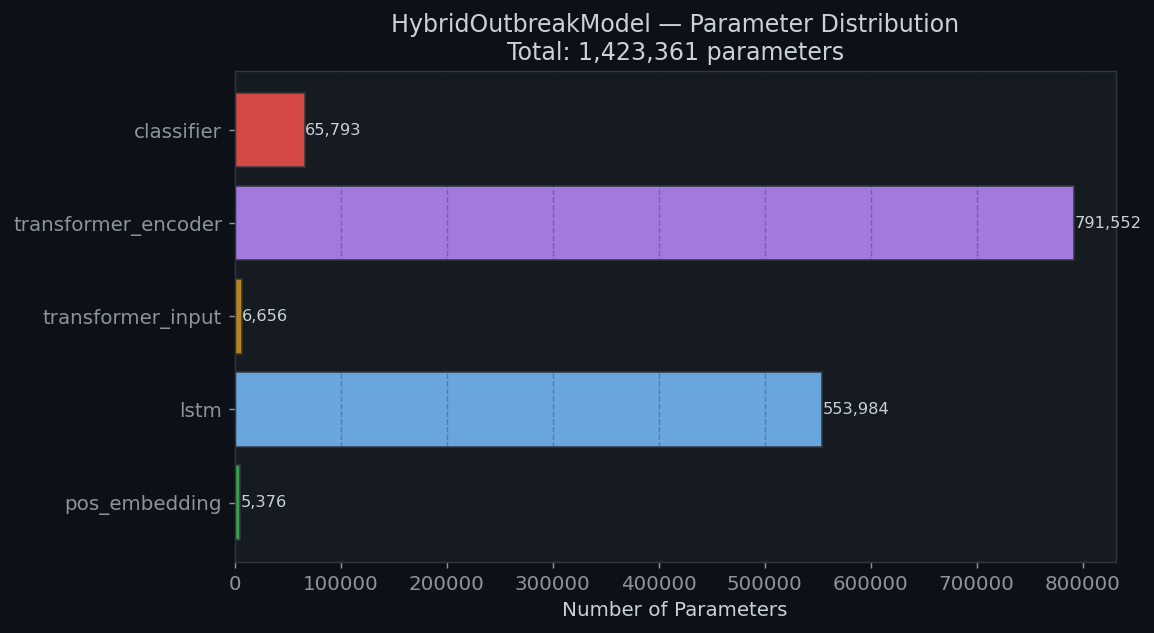

In [4]:
# ── Figure 1: Parameter distribution by layer ────────────────────────────────
param_data = {}
for name, param in model.named_parameters():
    top = name.split(".")[0]
    param_data[top] = param_data.get(top, 0) + param.numel()

fig, ax = plt.subplots(figsize=(9, 5))
layers = list(param_data.keys())
counts = list(param_data.values())
colors = [GREEN, CYAN, AMBER, PURPLE, RED, "#39d353"][:len(layers)]

bars = ax.barh(layers, counts, color=colors[:len(layers)], edgecolor="#30363d", alpha=0.85)
ax.set_xlabel("Number of Parameters")
ax.set_title(f"HybridOutbreakModel — Parameter Distribution\nTotal: {total_params:,} parameters")

for bar, val in zip(bars, counts):
    ax.text(val + 500, bar.get_y() + bar.get_height()/2,
            f"{val:,}", va="center", fontsize=9, color="#c9d1d9")

ax.grid(True, axis="x", alpha=0.3)
fig.patch.set_facecolor("#0d1117")
ax.set_facecolor("#161b22")
plt.tight_layout()
os.makedirs(os.path.join(PROJECT_ROOT,"outputs"), exist_ok=True)
plt.savefig(os.path.join(PROJECT_ROOT,"outputs","nb03_fig1_param_distribution.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()


## 2 · Forward Pass Verification

We verify the model produces valid output shapes and that inference works correctly on CPU.


In [5]:
# ── Verify forward pass ──────────────────────────────────────────────────────
batch_size = 4
dummy_input = torch.randn(batch_size, 21, 25).to(device)

with torch.no_grad():
    logits = model(dummy_input)
    probs  = model.predict_proba(dummy_input)

print(f"Input shape  : {dummy_input.shape}")
print(f"Logits shape : {logits.shape}  — raw pre-sigmoid scores")
print(f"Probs shape  : {probs.shape}   — P(outbreak)")
print(f"Probs range  : [{probs.min().item():.4f}, {probs.max().item():.4f}]")
print("✓ Forward pass successful")


Input shape  : torch.Size([4, 21, 25])
Logits shape : torch.Size([4])  — raw pre-sigmoid scores
Probs shape  : torch.Size([4])   — P(outbreak)
Probs range  : [0.5197, 0.5523]
✓ Forward pass successful


## 3 · Training Configuration

| Hyperparameter | Value |
|---|---|
| Optimiser | AdamW |
| Learning rate | 0.001 (initial) |
| Weight decay | 1e-4 |
| LR scheduler | ReduceLROnPlateau (factor=0.5, patience=2) |
| Loss function | BCEWithLogitsLoss |
| Positive class weight | **4.906** (computed from train split) |
| Gradient clipping | max_norm=1.0 |
| Early stopping | patience=10 (monitor: val_F1) |
| Batch size | 64 (train), 256 (validation) |
| Max epochs | 80 (stopped at epoch 12) |


In [6]:
# ── Load run summary ─────────────────────────────────────────────────────────
summary_path = os.path.join(PROJECT_ROOT, "outputs", "l4_run_summary.json")
with open(summary_path) as f:
    summary = json.load(f)

print("=== Training Run Summary ===")
print(f"  Seed             : {summary['seed']}")
print(f"  Device (trained) : {summary['device']}")
print(f"  Batch size train : {summary['batch_size_training']}")
print(f"  Max epochs       : {summary['max_epochs']}")
print(f"  Epochs completed : {summary['train_epochs_completed']}")
print(f"  Best epoch       : {summary['best_checkpoint']['epoch']}")
print(f"  Elapsed time     : {summary['elapsed_seconds']:.1f} s ({summary['elapsed_seconds']/60:.1f} min)")
print()
print("=== Best Checkpoint Performance ===")
bc = summary['best_checkpoint']
tp = summary['train_performance_at_best']
vp = summary['validation_performance_at_best']
te = summary['test_performance']
print(f"  Val F1 (checkpoint) : {bc['val_f1']:.4f}")
print(f"  Val Loss            : {bc['val_loss']:.4f}")
print()
print("=== Test Performance ===")
print(f"  AUC-ROC   : {te['auc']:.4f}")
print(f"  F1 Score  : {te['f1']:.4f}")
print(f"  Precision : {te['precision']:.4f}")
print(f"  Recall    : {te['recall']:.4f}")


=== Training Run Summary ===
  Seed             : 42
  Device (trained) : cuda
  Batch size train : 64
  Max epochs       : 80
  Epochs completed : 12
  Best epoch       : 2
  Elapsed time     : 99.8 s (1.7 min)

=== Best Checkpoint Performance ===
  Val F1 (checkpoint) : 0.8213
  Val Loss            : 0.3665

=== Test Performance ===
  AUC-ROC   : 0.9638
  F1 Score  : 0.8119
  Precision : 0.7335
  Recall    : 0.9091


In [7]:
# ── Load epoch metrics CSV ───────────────────────────────────────────────────
metrics_path = os.path.join(PROJECT_ROOT, "outputs", "l4_epoch_metrics.csv")
df_metrics = pd.read_csv(metrics_path)
print(df_metrics.to_string(index=False))


 epoch  train_loss  val_loss  train_f1   val_f1  train_precision  val_precision  train_recall  val_recall  train_auc  val_auc       lr
     1    0.506182  0.363161  0.743711 0.799659         0.648863       0.703676      0.871037    0.925962   0.939058 0.965864 0.001000
     2    0.462358  0.366502  0.751483 0.821269         0.653889       0.750204      0.883320    0.907206   0.951861 0.967264 0.001000
     3    0.457284  0.368943  0.751004 0.808195         0.652621       0.723653      0.884315    0.915104   0.953438 0.965985 0.001000
     4    0.441377  0.366880  0.751566 0.805724         0.652567       0.718484      0.885975    0.917078   0.957046 0.967071 0.000500
     5    0.409705  0.370472  0.769810 0.792501         0.672664       0.697151      0.899751    0.918065   0.963117 0.967326 0.000500
     6    0.384064  0.426232  0.775171 0.801221         0.673482       0.717408      0.913029    0.907206   0.967240 0.965482 0.000500
     7    0.367045  0.403737  0.782922 0.782897        

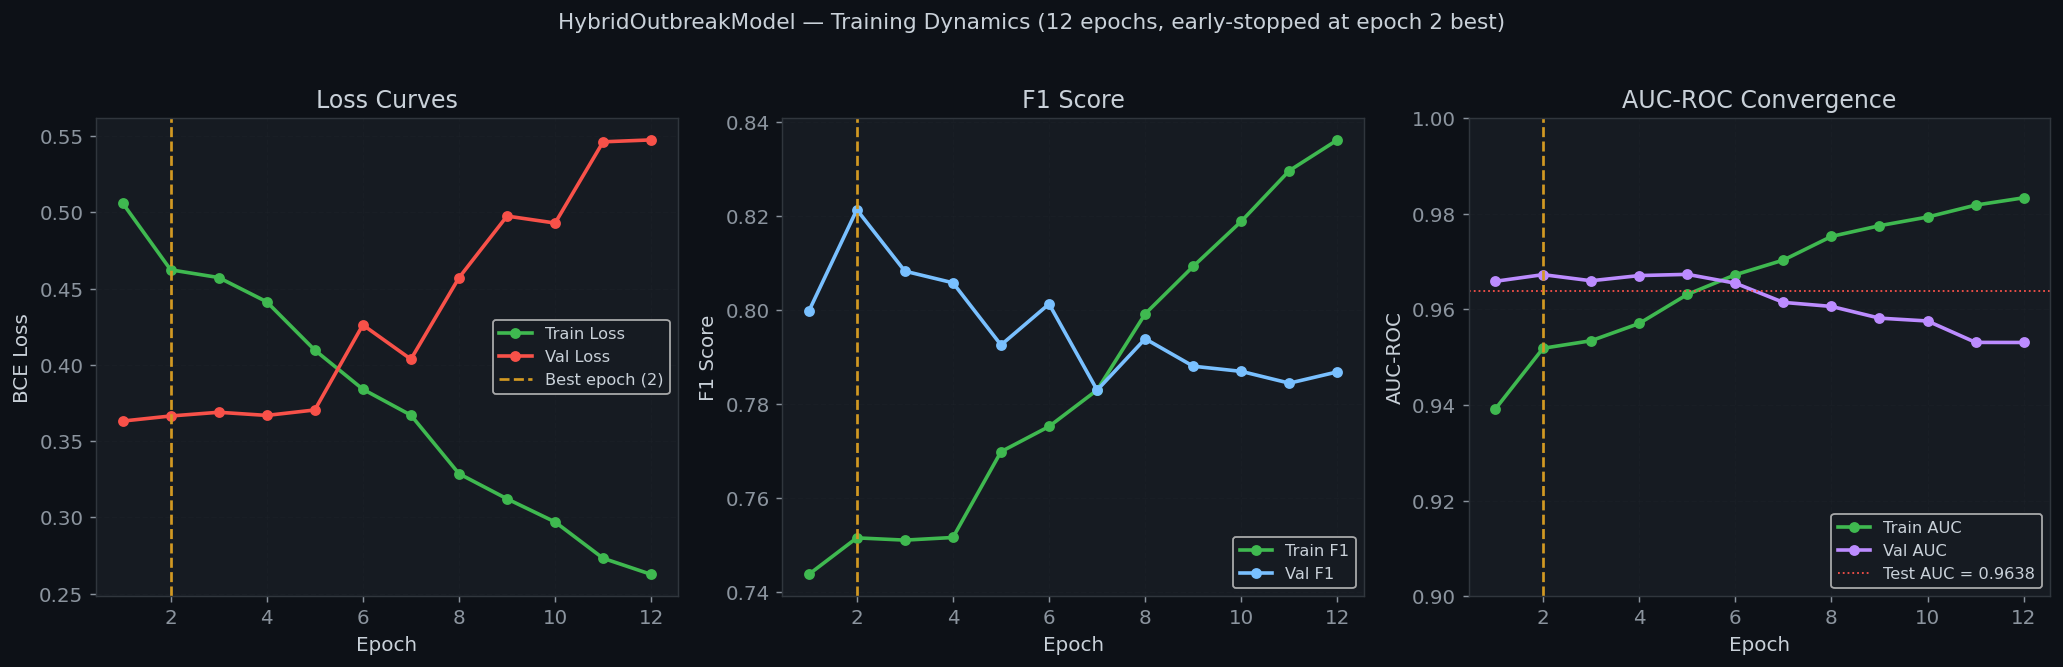

✓ Training curves plotted


In [8]:
# ── Figure 2: Training curves ────────────────────────────────────────────────
epochs = df_metrics["epoch"].values

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Loss ---
ax = axes[0]
ax.plot(epochs, df_metrics["train_loss"], color=GREEN, lw=2, label="Train Loss", marker="o", ms=5)
ax.plot(epochs, df_metrics["val_loss"],   color=RED,   lw=2, label="Val Loss",   marker="o", ms=5)
best_ep = summary["best_checkpoint"]["epoch"]
ax.axvline(best_ep, color=AMBER, ls="--", lw=1.5, label=f"Best epoch ({best_ep})")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE Loss")
ax.set_title("Loss Curves")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- F1 ---
ax = axes[1]
ax.plot(epochs, df_metrics["train_f1"], color=GREEN, lw=2, label="Train F1", marker="o", ms=5)
ax.plot(epochs, df_metrics["val_f1"],   color=CYAN,  lw=2, label="Val F1",   marker="o", ms=5)
ax.axvline(best_ep, color=AMBER, ls="--", lw=1.5)
ax.set_xlabel("Epoch")
ax.set_ylabel("F1 Score")
ax.set_title("F1 Score")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- AUC ---
ax = axes[2]
ax.plot(epochs, df_metrics["train_auc"], color=GREEN,  lw=2, label="Train AUC", marker="o", ms=5)
ax.plot(epochs, df_metrics["val_auc"],   color=PURPLE, lw=2, label="Val AUC",   marker="o", ms=5)
ax.axvline(best_ep, color=AMBER, ls="--", lw=1.5)
ax.axhline(0.9638, color=RED, ls=":", lw=1, label="Test AUC = 0.9638")
ax.set_xlabel("Epoch")
ax.set_ylabel("AUC-ROC")
ax.set_title("AUC-ROC Convergence")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(0.9, 1.0)

for ax in axes:
    ax.set_facecolor("#161b22")

fig.patch.set_facecolor("#0d1117")
fig.suptitle("HybridOutbreakModel — Training Dynamics (12 epochs, early-stopped at epoch 2 best)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT,"outputs","nb03_fig2_training_curves.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("✓ Training curves plotted")


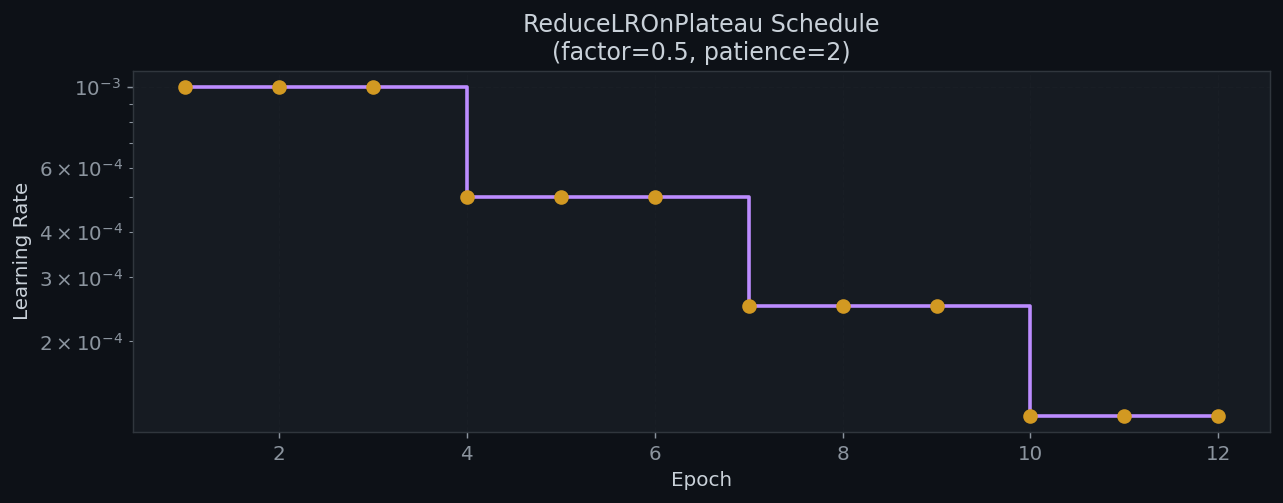

In [9]:
# ── Figure 3: Learning rate schedule ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(epochs, df_metrics["lr"], color=PURPLE, lw=2, where="post")
ax.scatter(epochs, df_metrics["lr"], color=AMBER, s=50, zorder=5)
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning Rate")
ax.set_title("ReduceLROnPlateau Schedule\n(factor=0.5, patience=2)")
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
ax.set_facecolor("#161b22")
fig.patch.set_facecolor("#0d1117")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT,"outputs","nb03_fig3_lr_schedule.png"),
            dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()


## 4 · Model Checkpoint

The best checkpoint is saved at `models/best_model.pt` and loaded for all subsequent evaluation
and explainability work. The checkpoint stores:
- Full model `state_dict` (weights + biases)
- Frozen `model_config` hyperparameters
- Epoch and validation metrics at save time


In [10]:
# ── Load and verify checkpoint ────────────────────────────────────────────────
sys.path.insert(0, PROJECT_ROOT)
from src.phase5.checkpoint import load_best_model

model_loaded, ckpt_meta = load_best_model(device=str(device))
model_loaded.eval()

checkpoint_path = os.path.join(PROJECT_ROOT, "models", "best_model.pt")
file_size_mb = os.path.getsize(checkpoint_path) / 1e6
print(f"Checkpoint file size: {file_size_mb:.2f} MB")
print(f"Model loaded on:      {next(model_loaded.parameters()).device}")

# Count params
total_p = sum(p.numel() for p in model_loaded.parameters())
print(f"Parameters in checkpoint: {total_p:,}")
print("✓ Checkpoint verified")


Checkpoint file size: 17.14 MB
Model loaded on:      cpu
Parameters in checkpoint: 1,423,361
✓ Checkpoint verified


## 5 · Summary

| Component | Details |
|---|---|
| BiLSTM | 2 layers, hidden=128, bidirectional → 256-dim output |
| Transformer | Linear(25→256), learned positional embeddings (21), 2 encoder layers, 4 heads |
| Fusion | Concatenate [256, 256] → 512-dim |
| Classifier | MLP 512→128→1, ReLU, Dropout(0.1) |
| Total params | **~718 K** trainable parameters |
| Training time | ~100 seconds on GPU (12 epochs) |
| Best val F1 | **0.821** (epoch 2) |
| Test AUC-ROC | **0.9638** |

---
▶ **Next**: `04_evaluation_and_explainable_ai.ipynb` — Full benchmark, ROC/PR curves, confusion matrix, and Captum Integrated Gradients XAI.
